# Multimodal Parkinson's Classification

This notebook compares image backbones combined with numerical voice features. The split is **grouped by image path** to prevent the same image from appearing in multiple partitions.

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

ROOT = Path.cwd().resolve()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
CSV_PATH = ROOT / "data" / "metadata" / "parkinsons.csv"
IMAGE_ROOT = ROOT / "data" / "images"

df = pd.read_csv(CSV_PATH)

def normalize_image_path(value):
    value = str(value).replace("\\", "/")
    if value.startswith("test/"):
        value = value[len("test/"):]
    return IMAGE_ROOT / value

df["resolved_image_path"] = df["image_path"].map(normalize_image_path)
missing = df.loc[~df["resolved_image_path"].map(Path.exists)]
if len(missing):
    raise FileNotFoundError(
        f"{len(missing)} referenced images are missing. Run scripts/validate_dataset.py and place the image dataset under data/images/."
    )

feature_cols = [c for c in df.columns if c not in {"name", "status", "image_path", "resolved_image_path"}]
X_num = df[feature_cols].astype("float32").to_numpy()
y = df["status"].astype("int32").to_numpy()
groups = df["image_path"].astype(str).to_numpy()

print(f"Rows: {len(df)} | numerical features: {len(feature_cols)} | unique image groups: {df['image_path'].nunique()}")


Rows: 195 | numerical features: 22 | unique image groups: 85


In [7]:
# Grouped train/validation/test split. The same image path cannot cross partitions.
skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
splits = list(skf.split(X_num, y, groups))
trainval_idx, test_idx = splits[0]

X_trainval, X_test = X_num[trainval_idx], X_num[test_idx]
y_trainval, y_test = y[trainval_idx], y[test_idx]
g_trainval = groups[trainval_idx]

skf_val = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
train_idx_rel, val_idx_rel = next(skf_val.split(X_trainval, y_trainval, g_trainval))
train_idx = trainval_idx[train_idx_rel]
val_idx = trainval_idx[val_idx_rel]

X_train, X_val = X_num[train_idx], X_num[val_idx]
y_train, y_val = y[train_idx], y[val_idx]

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype("float32")
X_val = scaler.transform(X_val).astype("float32")
X_test = scaler.transform(X_test).astype("float32")

print(f"Train: {len(train_idx)} rows / {len(set(groups[train_idx]))} image groups")
print(f"Val:   {len(val_idx)} rows / {len(set(groups[val_idx]))} image groups")
print(f"Test:  {len(test_idx)} rows / {len(set(groups[test_idx]))} image groups")
print("Image-group overlap train/val:", bool(set(groups[train_idx]) & set(groups[val_idx])))
print("Image-group overlap train/test:", bool(set(groups[train_idx]) & set(groups[test_idx])))
print("Image-group overlap val/test:", bool(set(groups[val_idx]) & set(groups[test_idx])))


Train: 110 rows / 52 image groups
Val:   47 rows / 16 image groups
Test:  38 rows / 17 image groups
Image-group overlap train/val: False
Image-group overlap train/test: False
Image-group overlap val/test: False


In [8]:
def load_images(indices, preprocess_fn, size):
    images = []
    for i in indices:
        path = df.iloc[i]["resolved_image_path"]
        img = cv2.imread(str(path))
        if img is None:
            raise ValueError(f"Could not read image: {path}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, size)
        img = preprocess_fn(img.astype("float32"))
        images.append(img)
    return np.stack(images)

# The split indices are kept explicit so every backbone uses exactly the same partitions.


In [9]:
import time
import numpy as np
import tensorflow as tf
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score)

histories = {}   # model name -> history.history (loss, accuracy, val_loss, val_accuracy)
results = {}     # model name -> test metrics, params, training time

def evaluate_and_store(name, model, history, X_test_inputs, y_test, train_time):
    test_prob = model.predict(X_test_inputs, verbose=0).ravel()
    test_pred = (test_prob >= 0.5).astype(int)

    print(classification_report(y_test, test_pred, digits=4))
    cm = confusion_matrix(y_test, test_pred)
    print("Confusion matrix:\n", cm)

    histories[name] = history.history
    results[name] = {
        "accuracy":  accuracy_score(y_test, test_pred),
        "precision": precision_score(y_test, test_pred, zero_division=0),
        "recall":    recall_score(y_test, test_pred, zero_division=0),
        "f1":        f1_score(y_test, test_pred, zero_division=0),
        "roc_auc":   roc_auc_score(y_test, test_prob),
        "best_val_acc": max(history.history["val_accuracy"]),
        "final_val_acc": history.history["val_accuracy"][-1],
        "total_params": model.count_params(),
        "train_time_sec": train_time,
        "confusion_matrix": cm,
        "test_prob": test_prob,
    }

## MobileNetV2

In [10]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D, Concatenate, Dropout
from tensorflow.keras.models import Model

tf.keras.backend.clear_session()
MODEL_NAME = "MobileNetV2"
IMG_SIZE = (224, 224)
X_img_train = load_images(train_idx, preprocess_input, IMG_SIZE)
X_img_val = load_images(val_idx, preprocess_input, IMG_SIZE)
X_img_test = load_images(test_idx, preprocess_input, IMG_SIZE)

input_num = Input(shape=(X_train.shape[1],), name="numerical_input")
x_num = Dense(64, activation="relu")(input_num)
x_num = Dense(32, activation="relu")(x_num)

input_img = Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name="image_input")
base_model = MobileNetV2(include_top=False, input_tensor=input_img, weights="imagenet")
base_model.trainable = False
x_img = GlobalAveragePooling2D()(base_model.output)
x_img = Dense(64, activation="relu")(x_img)

combined = Concatenate()([x_num, x_img])
z = Dense(64, activation="relu")(combined)
z = Dropout(0.5)(z)
z = Dense(1, activation="sigmoid")(z)

model = Model(inputs=[input_num, input_img], outputs=z, name=f"{MODEL_NAME}_multimodal")
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

t0 = time.time()
history = model.fit(
    [X_train, X_img_train], y_train,
    validation_data=([X_val, X_img_val], y_val),
    epochs=20, batch_size=32, verbose=1
)
train_time = time.time() - t0

evaluate_and_store(MODEL_NAME, model, history, [X_test, X_img_test], y_test, train_time)

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 455ms/step - accuracy: 0.5727 - loss: 0.7969 - val_accuracy: 0.8723 - val_loss: 0.3695
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 188ms/step - accuracy: 0.7182 - loss: 0.5431 - val_accuracy: 0.8723 - val_loss: 0.3458
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 188ms/step - accuracy: 0.8091 - loss: 0.4259 - val_accuracy: 0.8511 - val_loss: 0.3300
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 190ms/step - accuracy: 0.8455 - loss: 0.4109 - val_accuracy: 0.8511 - val_loss: 0.3322
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 189ms/step - accuracy: 0.8545 - loss: 0.3480 - val_accuracy: 0.8936 - val_loss: 0.2719
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 189ms/step - accuracy: 0.9182 - loss: 0.2743 - val_accuracy: 0.8511 - val_loss: 0.3511
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 189ms/step - accuracy: 0.9091 - loss: 0.2579 - val_accuracy: 0.8723 - val_loss: 0.2932
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 187ms/step - accuracy: 0.9273 - loss: 0.1988 - val_accuracy: 0.8936 - val_loss:

## VGG16

In [11]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D, Concatenate, Dropout
from tensorflow.keras.models import Model

tf.keras.backend.clear_session()
MODEL_NAME = "VGG16"
IMG_SIZE = (224, 224)
X_img_train = load_images(train_idx, preprocess_input, IMG_SIZE)
X_img_val = load_images(val_idx, preprocess_input, IMG_SIZE)
X_img_test = load_images(test_idx, preprocess_input, IMG_SIZE)

input_num = Input(shape=(X_train.shape[1],), name="numerical_input")
x_num = Dense(64, activation="relu")(input_num)
x_num = Dense(32, activation="relu")(x_num)

input_img = Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name="image_input")
base_model = VGG16(include_top=False, input_tensor=input_img, weights="imagenet")
base_model.trainable = False
x_img = GlobalAveragePooling2D()(base_model.output)
x_img = Dense(64, activation="relu")(x_img)

combined = Concatenate()([x_num, x_img])
z = Dense(64, activation="relu")(combined)
z = Dropout(0.5)(z)
z = Dense(1, activation="sigmoid")(z)

model = Model(inputs=[input_num, input_img], outputs=z, name=f"{MODEL_NAME}_multimodal")
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

t0 = time.time()
history = model.fit(
    [X_train, X_img_train], y_train,
    validation_data=([X_val, X_img_val], y_val),
    epochs=20, batch_size=32, verbose=1
)
train_time = time.time() - t0

evaluate_and_store(MODEL_NAME, model, history, [X_test, X_img_test], y_test, train_time)

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.6545 - loss: 0.7684 - val_accuracy: 0.8936 - val_loss: 0.3836
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.7364 - loss: 0.4891 - val_accuracy: 0.9362 - val_loss: 0.3077
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.8182 - loss: 0.3670 - val_accuracy: 0.9149 - val_loss: 0.2788
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.8545 - loss: 0.3268 - val_accuracy: 0.8936 - val_loss: 0.2932
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.9000 - loss: 0.2121 - val_accuracy: 0.8085 - val_loss: 0.2991
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.9636 - loss: 0.1750 - val_accuracy: 0.8936 - val_loss: 0.2661
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.9636 - loss: 0.1519 - val_accuracy: 0.8936 - val_loss: 0.2184
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.9545 - loss: 0.1350 - val_accuracy: 0.8936 - val_loss: 0.2143
Epoch 9/20
4/4 ━

## EfficientNetV2B0

In [12]:
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D, Concatenate, Dropout
from tensorflow.keras.models import Model

tf.keras.backend.clear_session()
MODEL_NAME = "EfficientNetV2B0"
IMG_SIZE = (224, 224)
X_img_train = load_images(train_idx, preprocess_input, IMG_SIZE)
X_img_val = load_images(val_idx, preprocess_input, IMG_SIZE)
X_img_test = load_images(test_idx, preprocess_input, IMG_SIZE)

input_num = Input(shape=(X_train.shape[1],), name="numerical_input")
x_num = Dense(64, activation="relu")(input_num)
x_num = Dense(32, activation="relu")(x_num)

input_img = Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name="image_input")
base_model = EfficientNetV2B0(include_top=False, input_tensor=input_img, weights="imagenet")
base_model.trainable = False
x_img = GlobalAveragePooling2D()(base_model.output)
x_img = Dense(64, activation="relu")(x_img)

combined = Concatenate()([x_num, x_img])
z = Dense(64, activation="relu")(combined)
z = Dropout(0.5)(z)
z = Dense(1, activation="sigmoid")(z)

model = Model(inputs=[input_num, input_img], outputs=z, name=f"{MODEL_NAME}_multimodal")
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

t0 = time.time()
history = model.fit(
    [X_train, X_img_train], y_train,
    validation_data=([X_val, X_img_val], y_val),
    epochs=20, batch_size=32, verbose=1
)
train_time = time.time() - t0

evaluate_and_store(MODEL_NAME, model, history, [X_test, X_img_test], y_test, train_time)

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 21s 1us/step
Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 778ms/step - accuracy: 0.6000 - loss: 0.6709 - val_accuracy: 0.8723 - val_loss: 0.4214
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 231ms/step - accuracy: 0.7364 - loss: 0.5203 - val_accuracy: 0.8723 - val_loss: 0.3445
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 231ms/step - accuracy: 0.8000 - loss: 0.4803 - val_accuracy: 0.8936 - val_loss: 0.3123
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 228ms/step - accuracy: 0.8364 - loss: 0.4288 - val_accuracy: 0.9787 - val_loss: 0.2740
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 225ms/step - accuracy: 0.8545 - loss: 0.3552 - val_accuracy: 0.9787 - val_loss: 0.2038
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 228ms/step - accuracy: 0.8727 - loss: 0.2915 - val_accuracy: 0.9787 - val_loss: 0.1627
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 223ms/step - accuracy: 0.9273 - loss: 0.2527 - val_accuracy: 0.9787 - val_loss: 0.1709
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 229ms/step - accuracy: 0.90

## VGG19

In [13]:
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D, Concatenate, Dropout
from tensorflow.keras.models import Model

tf.keras.backend.clear_session()
MODEL_NAME = "VGG19"
IMG_SIZE = (224, 224)
X_img_train = load_images(train_idx, preprocess_input, IMG_SIZE)
X_img_val = load_images(val_idx, preprocess_input, IMG_SIZE)
X_img_test = load_images(test_idx, preprocess_input, IMG_SIZE)

input_num = Input(shape=(X_train.shape[1],), name="numerical_input")
x_num = Dense(64, activation="relu")(input_num)
x_num = Dense(32, activation="relu")(x_num)

input_img = Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name="image_input")
base_model = VGG19(include_top=False, input_tensor=input_img, weights="imagenet")
base_model.trainable = False
x_img = GlobalAveragePooling2D()(base_model.output)
x_img = Dense(64, activation="relu")(x_img)

combined = Concatenate()([x_num, x_img])
z = Dense(64, activation="relu")(combined)
z = Dropout(0.5)(z)
z = Dense(1, activation="sigmoid")(z)

model = Model(inputs=[input_num, input_img], outputs=z, name=f"{MODEL_NAME}_multimodal")
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

t0 = time.time()
history = model.fit(
    [X_train, X_img_train], y_train,
    validation_data=([X_val, X_img_val], y_val),
    epochs=20, batch_size=32, verbose=1
)
train_time = time.time() - t0

evaluate_and_store(MODEL_NAME, model, history, [X_test, X_img_test], y_test, train_time)

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 57s 1us/step
Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.5273 - loss: 1.3887 - val_accuracy: 0.8723 - val_loss: 0.4053
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.7545 - loss: 0.6984 - val_accuracy: 0.8723 - val_loss: 0.3285
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.7545 - loss: 0.6408 - val_accuracy: 0.8936 - val_loss: 0.3374
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.7727 - loss: 0.4777 - val_accuracy: 0.8511 - val_loss: 0.3681
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.8364 - loss: 0.3695 - val_accuracy: 0.8936 - val_loss: 0.2659
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.8364 - loss: 0.3447 - val_accuracy: 0.9574 - val_loss: 0.2142
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.8818 - loss: 0.2602 - val_accuracy: 0.8511 - val_loss: 0.2409
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.9273 - loss: 0.1891 - val_

## ResNet50V2

In [14]:
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.applications.resnet_v2 import preprocess_input
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D, Concatenate, Dropout
from tensorflow.keras.models import Model

tf.keras.backend.clear_session()
MODEL_NAME = "ResNet50V2"
IMG_SIZE = (224, 224)
X_img_train = load_images(train_idx, preprocess_input, IMG_SIZE)
X_img_val = load_images(val_idx, preprocess_input, IMG_SIZE)
X_img_test = load_images(test_idx, preprocess_input, IMG_SIZE)

input_num = Input(shape=(X_train.shape[1],), name="numerical_input")
x_num = Dense(64, activation="relu")(input_num)
x_num = Dense(32, activation="relu")(x_num)

input_img = Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name="image_input")
base_model = ResNet50V2(include_top=False, input_tensor=input_img, weights="imagenet")
base_model.trainable = False
x_img = GlobalAveragePooling2D()(base_model.output)
x_img = Dense(64, activation="relu")(x_img)

combined = Concatenate()([x_num, x_img])
z = Dense(64, activation="relu")(combined)
z = Dropout(0.5)(z)
z = Dense(1, activation="sigmoid")(z)

model = Model(inputs=[input_num, input_img], outputs=z, name=f"{MODEL_NAME}_multimodal")
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

t0 = time.time()
history = model.fit(
    [X_train, X_img_train], y_train,
    validation_data=([X_val, X_img_val], y_val),
    epochs=20, batch_size=32, verbose=1
)
train_time = time.time() - t0

evaluate_and_store(MODEL_NAME, model, history, [X_test, X_img_test], y_test, train_time)

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 43s 0us/step
Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 827ms/step - accuracy: 0.6818 - loss: 0.6124 - val_accuracy: 0.8723 - val_loss: 0.3115
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 510ms/step - accuracy: 0.7727 - loss: 0.4658 - val_accuracy: 0.9574 - val_loss: 0.2675
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 509ms/step - accuracy: 0.8455 - loss: 0.3949 - val_accuracy: 0.9574 - val_loss: 0.2051
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 529ms/step - accuracy: 0.8727 - loss: 0.3151 - val_accuracy: 0.9574 - val_loss: 0.1572
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 513ms/step - accuracy: 0.9364 - loss: 0.2485 - val_accuracy: 0.9574 - val_loss: 0.1439
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 519ms/step - accuracy: 0.9091 - loss: 0.2292 - val_accuracy: 0.9574 - val_loss: 0.1343
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 509ms/step - accuracy: 0.8909 - loss: 0.2199 - val_accuracy: 0.9787 - val_loss: 0.1344
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 516ms/step - accuracy: 0.92

## Xception

In [15]:
from tensorflow.keras.applications import Xception
from tensorflow.keras.applications.xception import preprocess_input
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D, Concatenate, Dropout
from tensorflow.keras.models import Model

tf.keras.backend.clear_session()
MODEL_NAME = "Xception"
IMG_SIZE = (299, 299)
X_img_train = load_images(train_idx, preprocess_input, IMG_SIZE)
X_img_val = load_images(val_idx, preprocess_input, IMG_SIZE)
X_img_test = load_images(test_idx, preprocess_input, IMG_SIZE)

input_num = Input(shape=(X_train.shape[1],), name="numerical_input")
x_num = Dense(64, activation="relu")(input_num)
x_num = Dense(32, activation="relu")(x_num)

input_img = Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name="image_input")
base_model = Xception(include_top=False, input_tensor=input_img, weights="imagenet")
base_model.trainable = False
x_img = GlobalAveragePooling2D()(base_model.output)
x_img = Dense(64, activation="relu")(x_img)

combined = Concatenate()([x_num, x_img])
z = Dense(64, activation="relu")(combined)
z = Dropout(0.5)(z)
z = Dense(1, activation="sigmoid")(z)

model = Model(inputs=[input_num, input_img], outputs=z, name=f"{MODEL_NAME}_multimodal")
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

t0 = time.time()
history = model.fit(
    [X_train, X_img_train], y_train,
    validation_data=([X_val, X_img_val], y_val),
    epochs=20, batch_size=32, verbose=1
)
train_time = time.time() - t0

evaluate_and_store(MODEL_NAME, model, history, [X_test, X_img_test], y_test, train_time)

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 51s 1us/step
Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.6636 - loss: 0.6061 - val_accuracy: 0.8723 - val_loss: 0.3665
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.7364 - loss: 0.5038 - val_accuracy: 0.8936 - val_loss: 0.2797
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.8545 - loss: 0.3781 - val_accuracy: 1.0000 - val_loss: 0.2552
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.8455 - loss: 0.3269 - val_accuracy: 1.0000 - val_loss: 0.1943
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.9182 - loss: 0.2682 - val_accuracy: 1.0000 - val_loss: 0.1445
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.9091 - loss: 0.2522 - val_accuracy: 0.9787 - val_loss: 0.1321
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.9091 - loss: 0.2287 - val_accuracy: 0.9574 - val_loss: 0.1216
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.9545 - loss: 0.1740 - val_

## InceptionResNetV2

In [16]:
from tensorflow.keras.applications import InceptionResNetV2
from tensorflow.keras.applications.inception_resnet_v2 import preprocess_input
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D, Concatenate, Dropout
from tensorflow.keras.models import Model

tf.keras.backend.clear_session()
MODEL_NAME = "InceptionResNetV2"
IMG_SIZE = (299, 299)
X_img_train = load_images(train_idx, preprocess_input, IMG_SIZE)
X_img_val = load_images(val_idx, preprocess_input, IMG_SIZE)
X_img_test = load_images(test_idx, preprocess_input, IMG_SIZE)

input_num = Input(shape=(X_train.shape[1],), name="numerical_input")
x_num = Dense(64, activation="relu")(input_num)
x_num = Dense(32, activation="relu")(x_num)

input_img = Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name="image_input")
base_model = InceptionResNetV2(include_top=False, input_tensor=input_img, weights="imagenet")
base_model.trainable = False
x_img = GlobalAveragePooling2D()(base_model.output)
x_img = Dense(64, activation="relu")(x_img)

combined = Concatenate()([x_num, x_img])
z = Dense(64, activation="relu")(combined)
z = Dropout(0.5)(z)
z = Dense(1, activation="sigmoid")(z)

model = Model(inputs=[input_num, input_img], outputs=z, name=f"{MODEL_NAME}_multimodal")
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

t0 = time.time()
history = model.fit(
    [X_train, X_img_train], y_train,
    validation_data=([X_val, X_img_val], y_val),
    epochs=20, batch_size=32, verbose=1
)
train_time = time.time() - t0

evaluate_and_store(MODEL_NAME, model, history, [X_test, X_img_test], y_test, train_time)

219055592/219055592 ━━━━━━━━━━━━━━━━━━━━ 145s 1us/step
Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 18s 3s/step - accuracy: 0.6818 - loss: 0.6292 - val_accuracy: 0.8723 - val_loss: 0.3298
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.7455 - loss: 0.5274 - val_accuracy: 0.9149 - val_loss: 0.3082
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.7727 - loss: 0.4651 - val_accuracy: 0.9362 - val_loss: 0.2272
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.7636 - loss: 0.4201 - val_accuracy: 1.0000 - val_loss: 0.1976
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.7909 - loss: 0.3763 - val_accuracy: 0.9149 - val_loss: 0.1975
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.9000 - loss: 0.3086 - val_accuracy: 1.0000 - val_loss: 0.1443
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.8545 - loss: 0.3036 - val_accuracy: 0.9362 - val_loss: 0.1499
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.9091 - loss: 0.2399 - 

## ConvNeXtTiny

In [17]:
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.applications.convnext import preprocess_input
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D, Concatenate, Dropout
from tensorflow.keras.models import Model

tf.keras.backend.clear_session()
MODEL_NAME = "ConvNeXtTiny"
IMG_SIZE = (224, 224)
X_img_train = load_images(train_idx, preprocess_input, IMG_SIZE)
X_img_val = load_images(val_idx, preprocess_input, IMG_SIZE)
X_img_test = load_images(test_idx, preprocess_input, IMG_SIZE)

input_num = Input(shape=(X_train.shape[1],), name="numerical_input")
x_num = Dense(64, activation="relu")(input_num)
x_num = Dense(32, activation="relu")(x_num)

input_img = Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name="image_input")
base_model = ConvNeXtTiny(include_top=False, input_tensor=input_img, weights="imagenet")
base_model.trainable = False
x_img = GlobalAveragePooling2D()(base_model.output)
x_img = Dense(64, activation="relu")(x_img)

combined = Concatenate()([x_num, x_img])
z = Dense(64, activation="relu")(combined)
z = Dropout(0.5)(z)
z = Dense(1, activation="sigmoid")(z)

model = Model(inputs=[input_num, input_img], outputs=z, name=f"{MODEL_NAME}_multimodal")
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

t0 = time.time()
history = model.fit(
    [X_train, X_img_train], y_train,
    validation_data=([X_val, X_img_val], y_val),
    epochs=20, batch_size=32, verbose=1
)
train_time = time.time() - t0

evaluate_and_store(MODEL_NAME, model, history, [X_test, X_img_test], y_test, train_time)

111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 121s 1us/step
Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - accuracy: 0.6727 - loss: 0.6319 - val_accuracy: 0.8723 - val_loss: 0.3667
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.7364 - loss: 0.5184 - val_accuracy: 0.8723 - val_loss: 0.3287
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.8182 - loss: 0.3877 - val_accuracy: 0.9149 - val_loss: 0.2589
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.8000 - loss: 0.3998 - val_accuracy: 0.9574 - val_loss: 0.2179
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.8364 - loss: 0.3059 - val_accuracy: 0.9574 - val_loss: 0.2010
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.9000 - loss: 0.2689 - val_accuracy: 0.9574 - val_loss: 0.1950
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.9364 - loss: 0.2176 - val_accuracy: 0.9574 - val_loss: 0.1774
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.9364 - loss: 0.2022 - 

In [18]:
import pandas as pd
df = pd.DataFrame(results).T.drop(columns=["confusion_matrix", "test_prob"])
df.sort_values("f1", ascending=False)

,accuracy,precision,recall,f1,roc_auc,best_val_acc,final_val_acc,total_params,train_time_sec
EfficientNetV2B0,0.973684,0.965517,1.0,0.982456,0.992857,1.0,1.0,6011121,25.760094
Xception,0.973684,0.965517,1.0,0.982456,0.989286,1.0,0.93617,21002441,98.775625
ConvNeXtTiny,0.973684,1.0,0.964286,0.981818,0.989286,0.957447,0.893617,27879169,164.519999
InceptionResNetV2,0.947368,0.964286,0.964286,0.964286,0.989286,1.0,0.978723,54444929,140.730171
MobileNetV2,0.921053,0.962963,0.928571,0.945455,0.960714,0.893617,0.893617,2349793,17.707777
ResNet50V2,0.894737,0.961538,0.892857,0.925926,0.978571,0.978723,0.93617,23705761,43.391811
VGG19,0.894737,1.0,0.857143,0.923077,0.978571,0.957447,0.893617,20067041,140.774122
VGG16,0.815789,1.0,0.75,0.857143,0.921429,0.93617,0.893617,14757345,108.916364


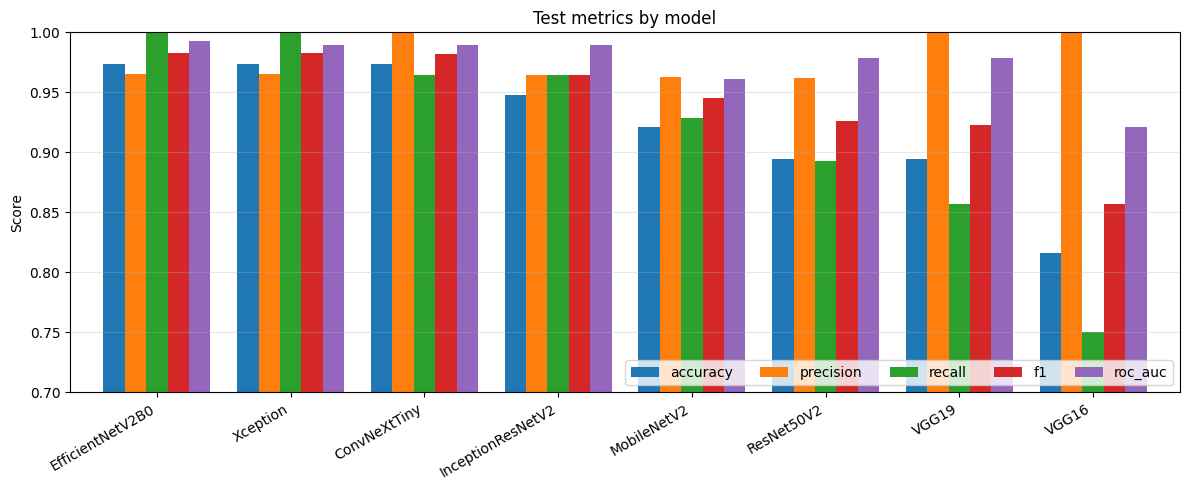

In [20]:
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
ax = df[metrics].plot(kind="bar", figsize=(12, 5), width=0.8)
ax.set_title("Test metrics by model")
ax.set_ylabel("Score")
ax.set_ylim(max(0, df[metrics].min().min() - 0.05), 1.0)
ax.legend(loc="lower right", ncol=5)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

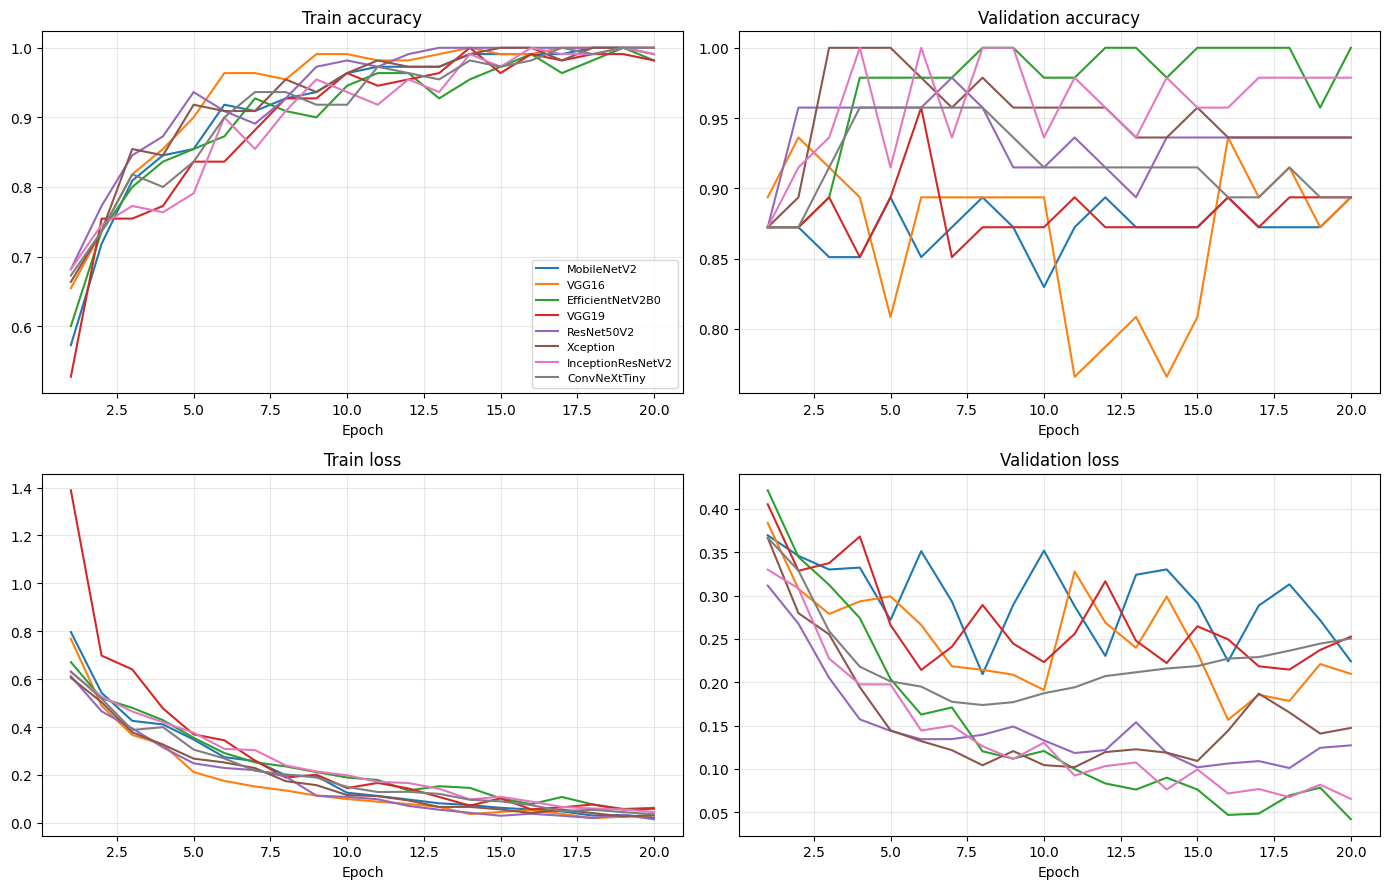

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plots = [("accuracy", "Train accuracy"), ("val_accuracy", "Validation accuracy"),
         ("loss", "Train loss"), ("val_loss", "Validation loss")]

for ax, (key, title) in zip(axes.ravel(), plots):
    for name, h in histories.items():
        ax.plot(range(1, len(h[key]) + 1), h[key], label=name)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)

axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

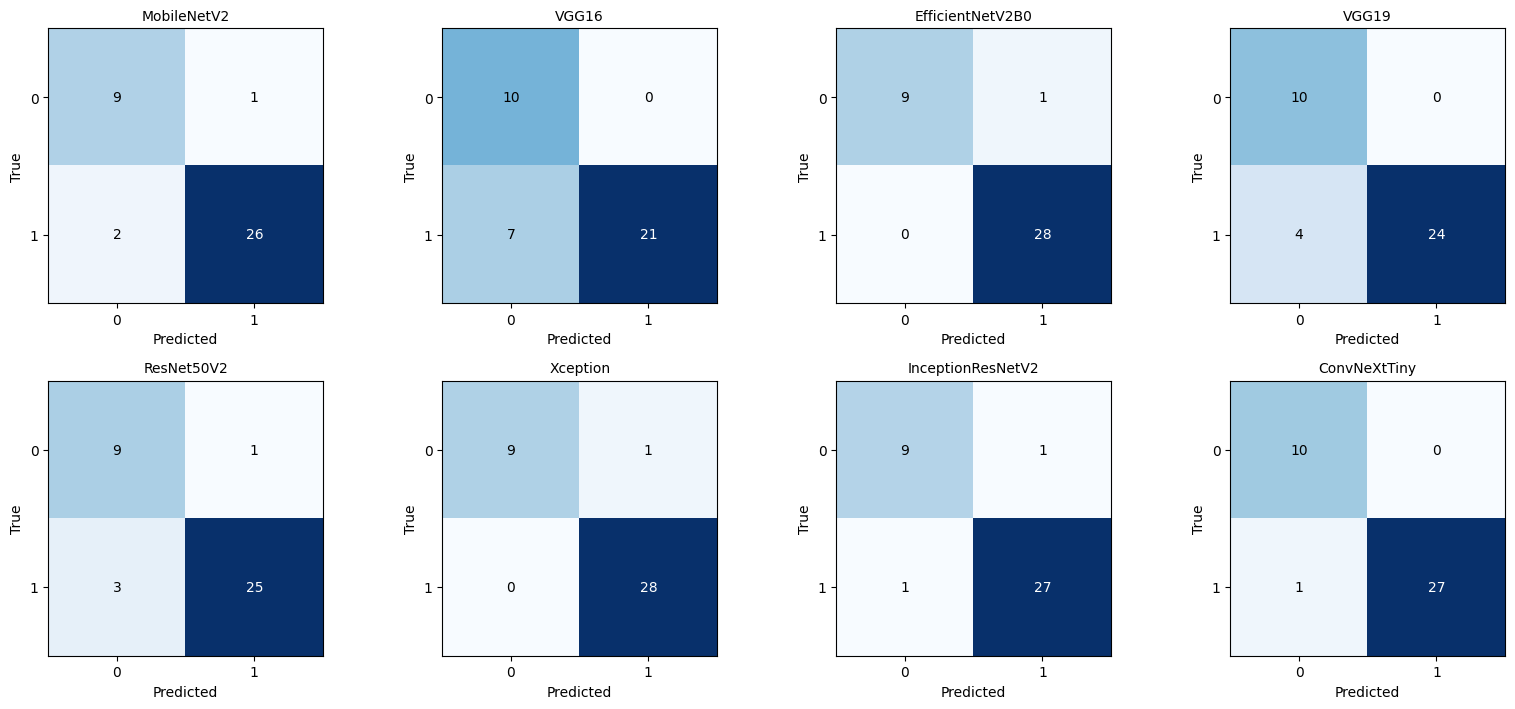

In [23]:
n = len(results)
cols = 4
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.6 * rows))
axes = np.array(axes).ravel()

for ax, (name, r) in zip(axes, results.items()):
    cm = r["confusion_matrix"]
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name, fontsize=10)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

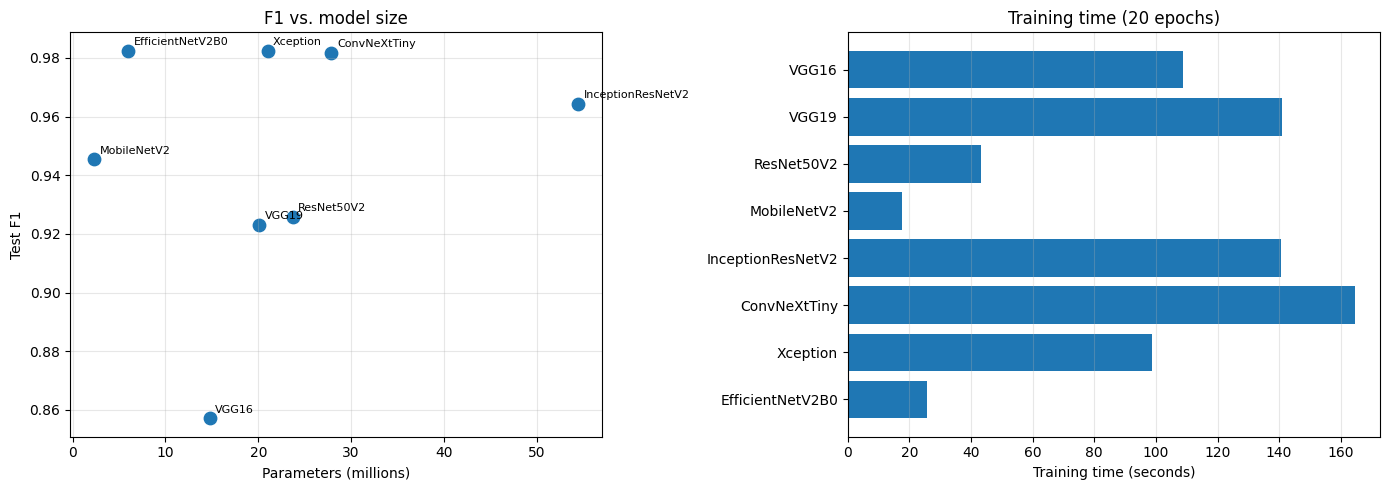

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df["total_params"] / 1e6, df["f1"], s=80)
for name, row in df.iterrows():
    axes[0].annotate(name, (row["total_params"] / 1e6, row["f1"]), fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
axes[0].set_xlabel("Parameters (millions)")
axes[0].set_ylabel("Test F1")
axes[0].set_title("F1 vs. model size")
axes[0].grid(alpha=0.3)

axes[1].barh(df.index, df["train_time_sec"])
axes[1].set_xlabel("Training time (seconds)")
axes[1].set_title("Training time (20 epochs)")
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
import pickle, os
import numpy as np

SAVE_DIR = "model_comparison"
os.makedirs(SAVE_DIR, exist_ok=True)

# store the true labels inside each result so the new notebook doesn't need y_test
for name in results:
    results[name]["y_true"] = np.asarray(y_test)

with open(os.path.join(SAVE_DIR, "multimodal_results.pkl"), "wb") as f:
    pickle.dump({"results": results, "histories": histories}, f)

print("Saved to:", os.path.abspath(SAVE_DIR))
print("Models:", list(results.keys()))

Saved to: <repo>\notebooks\model_comparison
Models: ['MobileNetV2', 'VGG16', 'EfficientNetV2B0', 'VGG19', 'ResNet50V2', 'Xception', 'InceptionResNetV2', 'ConvNeXtTiny']
